# Lab 5: Clustering Techniques Using DBSCAN and Hierarchical Clustering

**Course:** MSCS 634  
**Student Name:** Navya Katta  

### Libraries Used

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score,homogeneity_score,completeness_score)
from scipy.cluster.hierarchy import dendrogram, linkage

### Step 1: Data Preparation and Exploration

#### Load the Dataset

In [4]:
# Load the Wine dataset
wine = load_wine()

# Convert dataset into a Pandas DataFrame
df = pd.DataFrame(wine.data, columns=wine.feature_names)

# Display the first five rows
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


#### Examine Dataset structure

In [5]:
# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display dataset information
print("\nDataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (178, 13)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                     

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


#### Checking missing values

In [6]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Missing Values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Duplicate Records: 0


#### Standardize the Features

In [7]:
# Initialize StandardScaler
scaler = StandardScaler()

# Standardize the dataset
X_scaled = scaler.fit_transform(df)

# Convert standardized data into a DataFrame
df_scaled = pd.DataFrame(X_scaled, columns=df.columns)

# Display standardized data
df_scaled.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


#### Verify Standardization

In [8]:
# Verify the means and standard deviations
print("Mean of Standardized Features:")
print(df_scaled.mean().round(2))

print("\nStandard Deviation of Standardized Features:")
print(df_scaled.std(ddof=0).round(2))

Mean of Standardized Features:
alcohol                        -0.0
malic_acid                     -0.0
ash                            -0.0
alcalinity_of_ash              -0.0
magnesium                      -0.0
total_phenols                   0.0
flavanoids                     -0.0
nonflavanoid_phenols            0.0
proanthocyanins                -0.0
color_intensity                 0.0
hue                             0.0
od280/od315_of_diluted_wines    0.0
proline                        -0.0
dtype: float64

Standard Deviation of Standardized Features:
alcohol                         1.0
malic_acid                      1.0
ash                             1.0
alcalinity_of_ash               1.0
magnesium                       1.0
total_phenols                   1.0
flavanoids                      1.0
nonflavanoid_phenols            1.0
proanthocyanins                 1.0
color_intensity                 1.0
hue                             1.0
od280/od315_of_diluted_wines    1.0
proline 

### Step 2 – Hierarchical Clustering

#### Apply Agglomerative Hierarchical Clustering

In [9]:
# Apply Agglomerative Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=3,linkage='ward')
# Fit the model and predict cluster labels
hier_labels = hierarchical.fit_predict(X_scaled)
# Display cluster distribution
print("Hierarchical Clustering Results:")
print(pd.Series(hier_labels).value_counts().sort_index())

Hierarchical Clustering Results:
0    58
1    56
2    64
Name: count, dtype: int64


#### Experiment with Different Numbers of Clusters

In [10]:
# Test different numbers of clusters
cluster_range = [2, 3, 4, 5]
hier_results = []
for n in cluster_range:
    model = AgglomerativeClustering(n_clusters=n,linkage='ward')
    labels = model.fit_predict(X_scaled)
    silhouette = silhouette_score(X_scaled, labels)
    hier_results.append({'Number of Clusters': n,'Silhouette Score': silhouette})
# Display results
hier_results_df = pd.DataFrame(hier_results)
display(hier_results_df)

,Number of Clusters,Silhouette Score
0,2,0.267013
1,3,0.277444
2,4,0.225837
3,5,0.186742


#### Visualize Hierarchical Clustering Using PCA

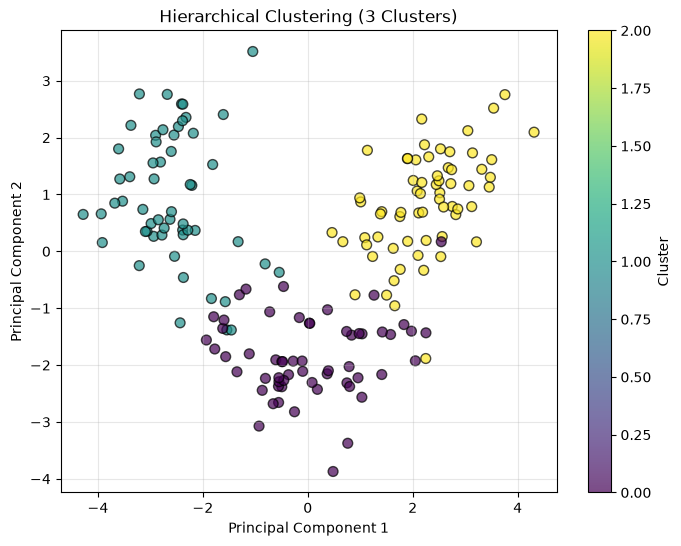

In [11]:
# Apply PCA for 2D visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
# Create scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0],X_pca[:, 1],c=hier_labels,cmap='viridis',s=50,edgecolor='black',alpha=0.7)
plt.title('Hierarchical Clustering (3 Clusters)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Cluster')
plt.grid(alpha=0.3)
plt.show()

#### Visualize Different Cluster Configurations

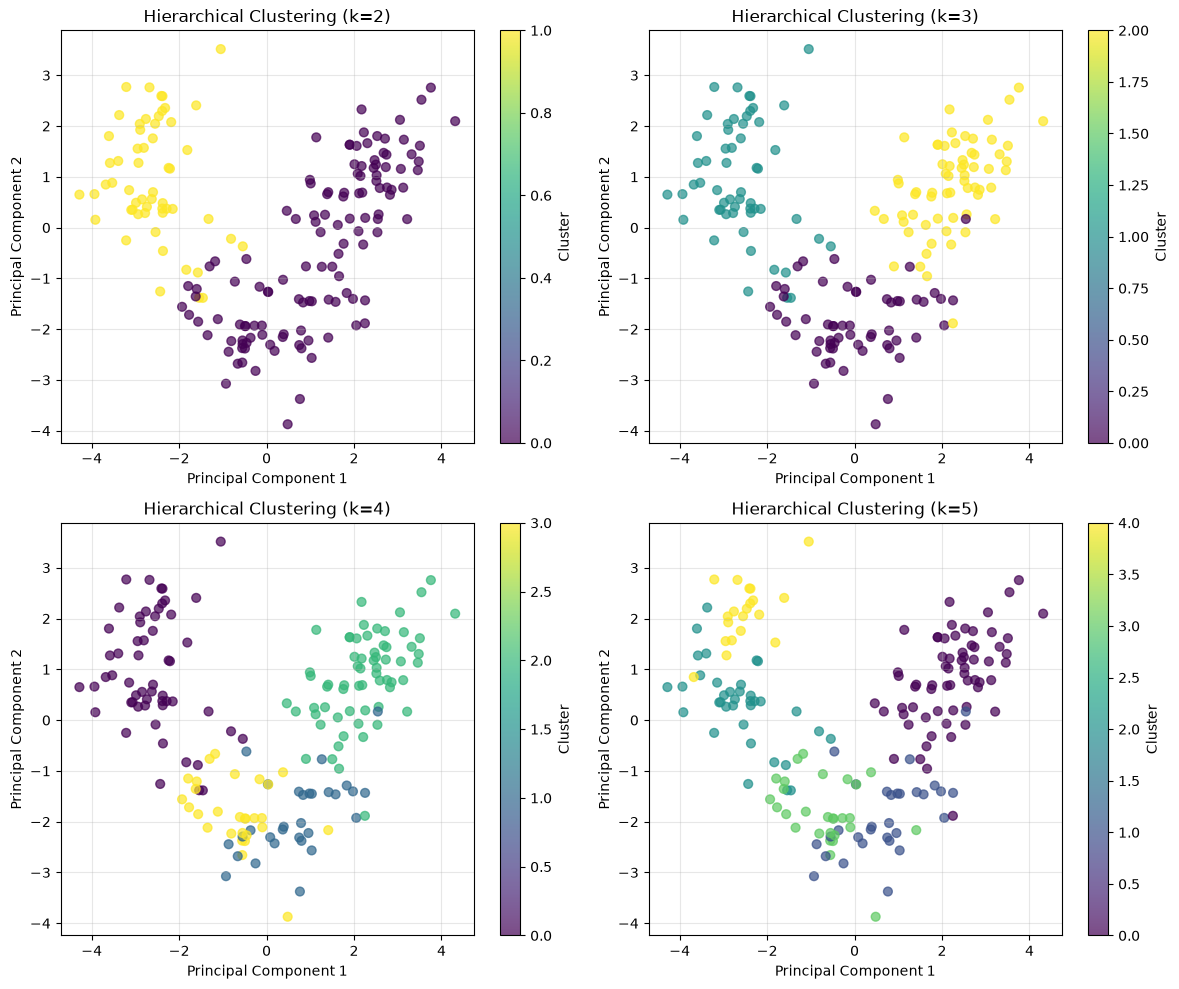

In [12]:
# Visualize different numbers of clusters
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, n in zip(axes.flatten(), cluster_range):
    model = AgglomerativeClustering(n_clusters=n,linkage='ward')
    labels = model.fit_predict(X_scaled)
    scatter = ax.scatter(X_pca[:, 0],X_pca[:, 1],c=labels,cmap='viridis',s=40,alpha=0.7)
    ax.set_title(f'Hierarchical Clustering (k={n})')
    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
    ax.grid(alpha=0.3)
    fig.colorbar(scatter, ax=ax, label='Cluster')
plt.tight_layout()
plt.show()

#### Generate a Dendrogram

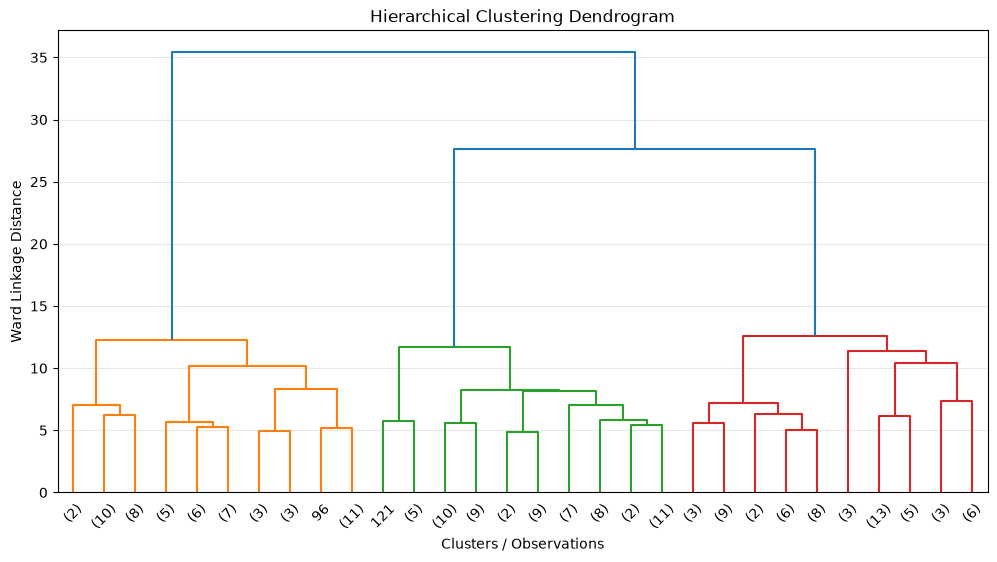

In [13]:
# Calculate hierarchical linkage matrix
linked = linkage(X_scaled, method='ward')

# Generate dendrogram
plt.figure(figsize=(12, 6))

dendrogram(linked,truncate_mode='lastp',p=30,show_leaf_counts=True)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Clusters / Observations')
plt.ylabel('Ward Linkage Distance')

plt.grid(axis='y', alpha=0.3)
plt.show()

### Step 3: DBSCAN Clustering

#### Apply DBSCAN Clustering

In [14]:
# Apply DBSCAN Clustering
dbscan = DBSCAN(eps=2.5, min_samples=5)

# Fit model and predict cluster labels
db_labels = dbscan.fit_predict(X_scaled)

# Display cluster distribution
print("DBSCAN Clustering Results:")
print(pd.Series(db_labels).value_counts().sort_index())

# Count clusters and noise points
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = np.sum(db_labels == -1)

print("\nNumber of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)

DBSCAN Clustering Results:
-1     24
 0    154
Name: count, dtype: int64

Number of Clusters: 1
Number of Noise Points: 24


#### Experiment with Different DBSCAN Parameters

In [15]:
# Define parameter values
eps_values = [1.5, 2.0, 2.5, 3.0, 3.5]
min_samples_values = [3, 5, 10]

dbscan_results = []

# Test different parameter combinations
for eps in eps_values:
    for min_samples in min_samples_values:
        model = DBSCAN(eps=eps, min_samples=min_samples)
        labels = model.fit_predict(X_scaled)
        # Count clusters excluding noise
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        # Count noise points
        n_noise = np.sum(labels == -1)
        # Calculate Silhouette Score when valid
        if 2 <= len(set(labels)) <= len(labels) - 1:
            silhouette = silhouette_score(X_scaled, labels)
        else:
            silhouette = np.nan
        dbscan_results.append({'eps': eps,'min_samples': min_samples,'Clusters': n_clusters,'Noise Points': n_noise,'Silhouette Score': silhouette})

# Convert results into DataFrame
dbscan_results_df = pd.DataFrame(dbscan_results)

display(dbscan_results_df)

,eps,min_samples,Clusters,Noise Points,Silhouette Score
0,1.5,3,8,147,-0.276769
1,1.5,5,0,178,NaN
2,1.5,10,0,178,NaN
3,2.0,3,5,64,0.031407
4,2.0,5,5,85,-0.032906
5,2.0,10,1,139,0.114510
6,2.5,3,1,23,0.135174
7,2.5,5,1,24,0.135004
8,2.5,10,2,32,0.204389
9,3.0,3,2,7,0.191097


#### Visualize DBSCAN Clusters Using PCA

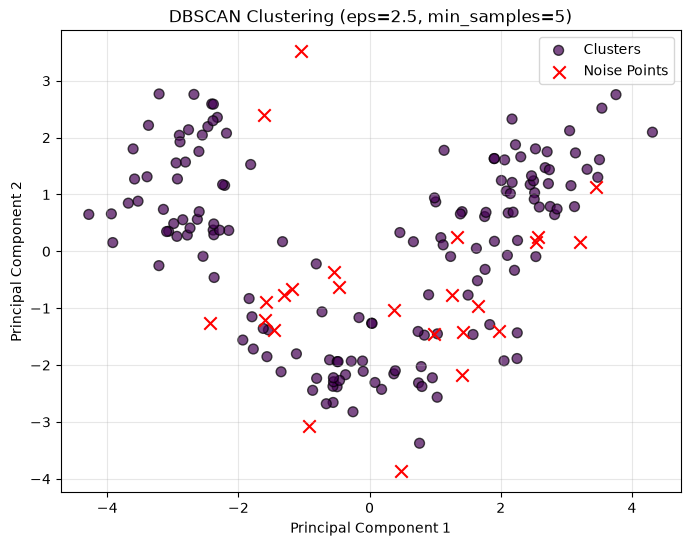

In [16]:
# Visualize DBSCAN Clustering
plt.figure(figsize=(8, 6))

# Plot clustered observations
plt.scatter(X_pca[db_labels != -1, 0],X_pca[db_labels != -1, 1],c=db_labels[db_labels != -1],cmap='viridis',s=50,alpha=0.7,edgecolor='black',
            label='Clusters')

# Highlight noise points
plt.scatter(X_pca[db_labels == -1, 0],X_pca[db_labels == -1, 1],c='red',marker='x',s=80,label='Noise Points')

plt.title('DBSCAN Clustering (eps=2.5, min_samples=5)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Evaluate DBSCAN Clustering Performance

In [18]:
# Actual class labels
true_labels = wine.target

# Exclude noise for cluster-quality evaluation
mask = db_labels != -1

# Number of clusters excluding noise
n_clusters = len(set(db_labels[mask]))

# Calculate Silhouette Score
if n_clusters >= 2 and mask.sum() > n_clusters:
    silhouette = silhouette_score(
        X_scaled[mask],
        db_labels[mask]
    )
else:
    silhouette = np.nan

# Calculate Homogeneity Score
homogeneity = homogeneity_score(true_labels, db_labels)

# Calculate Completeness Score
completeness = completeness_score(true_labels, db_labels)

# Display evaluation metrics
print("DBSCAN Evaluation Metrics")
print("-------------------------")

print("Silhouette Score:", round(silhouette, 4))
print("Homogeneity Score:", round(homogeneity, 4))
print("Completeness Score:", round(completeness, 4))

DBSCAN Evaluation Metrics
-------------------------
Silhouette Score: nan
Homogeneity Score: 0.0576
Completeness Score: 0.1581


#### Compare DBSCAN Parameter Configurations

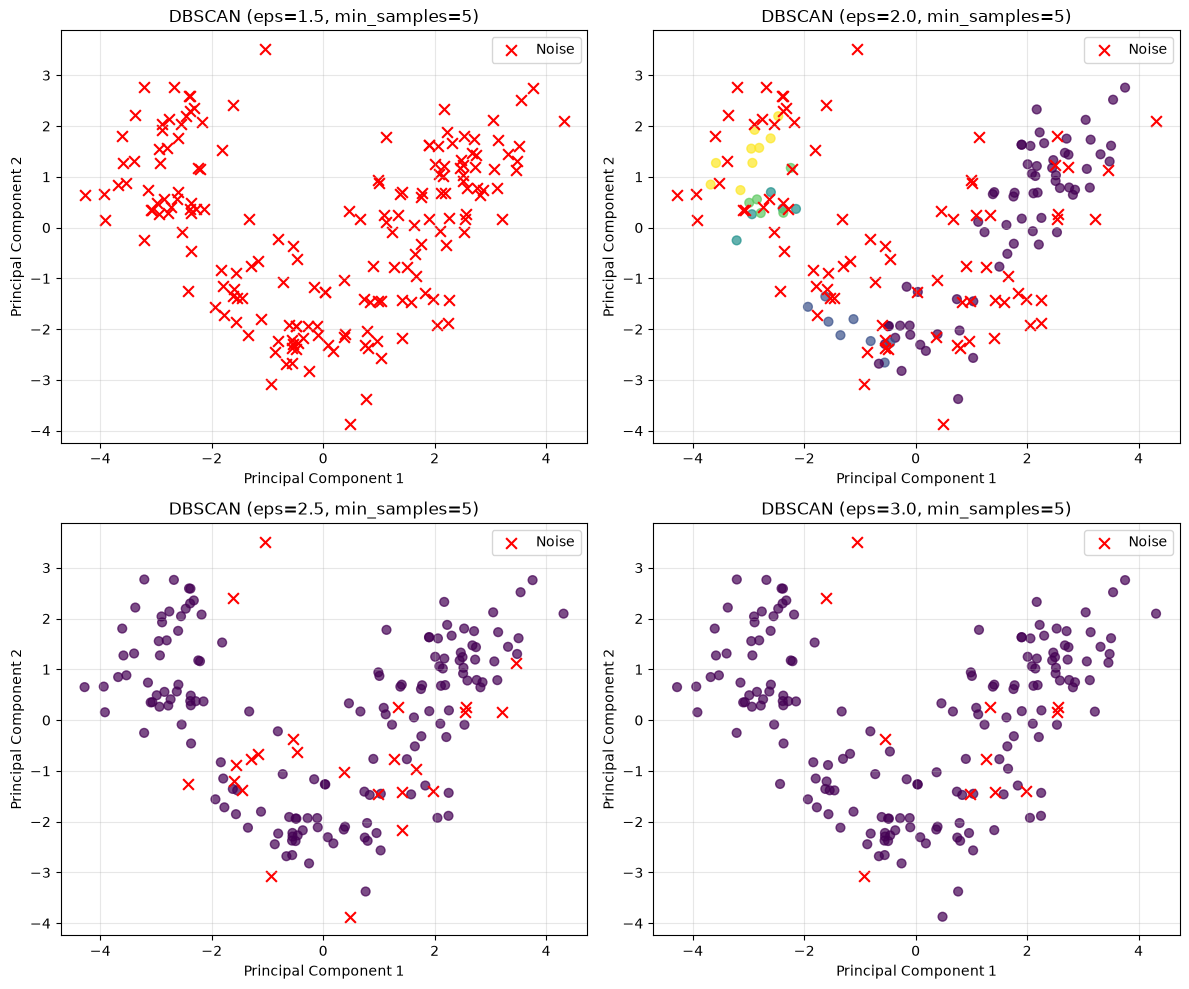

In [19]:
# Visualize different eps values
eps_comparison = [1.5, 2.0, 2.5, 3.0]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, eps in zip(axes.flatten(), eps_comparison):

    model = DBSCAN(eps=eps, min_samples=5)

    labels = model.fit_predict(X_scaled)

    # Plot clusters
    ax.scatter(X_pca[labels != -1, 0],X_pca[labels != -1, 1],c=labels[labels != -1],cmap='viridis',s=40,alpha=0.7)

    # Plot noise points
    ax.scatter(X_pca[labels == -1, 0],X_pca[labels == -1, 1],c='red',marker='x',s=60,label='Noise')

    ax.set_title(f'DBSCAN (eps={eps}, min_samples=5)')
    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Step 4: Analysis and Insights

The result is different for the two algorithms: Hierarchical Clustering and DBSCAN, when applied to the standardized Wine data. The best configuration for hierarchical clustering according to the Silhouette Score was the Ward linkage with three clusters (58 observations in the first, 56 observations in the second, and 64 observations in the third). In contrast, DBSCAN with eps=2.5 and min_samples=5 clusters into one cluster, which has 154 observations and 24 noise points. It had an agreement of 0.0576 in terms of its Homogeneity Score and 0.1581 in terms of its Completeness Score with the known classes of wine.

Both algorithms were strongly affected by the selection of the parameters. In the case of Hierarchical Clustering, the optimum number of clusters was three, as a higher number (four or five) lowered the Silhouette Score. DBSCAN was more sensitive to the changes of the parameters. Very small eps values yielded too many clusters while larger eps values caused observations to be grouped together. For instance, eps=1.5 and min_samples=5 resulted in all observations being labeled as noise while eps=3.5 yielded 6 noise observations.

The PCA, the dendrogram and the Hierarchical Clustering gave more meaningful clusters which were more interpretable. But it needs to be given the number of clusters and cannot explicitly identify noise. The parameters of DBSCAN are tuned automatically and are able to detect clusters in the data, as well as identify outliers, however, the process of tuning these parameters is not trivial, especially when dealing with high dimensional datasets.

In conclusion, HC was better on determining distinct groups in this experiment and DBSCAN was useful in detecting noise. The results emphasize the significance of parameters in clustering analysis and the need to standardize features.